# RotaSegura Limeira
### Acidentes de trânsito com motociclistas em Limeira (SP)

Global Solution 2026/2 – CitizenTech | Entrega técnica (3ª parte): análise de dados com Python

**Turma:** 1TSCO_ (preencher A ou B)
**Projeto:** RotaSegura Limeira
**Grupo:** (nome do grupo)

| Integrante | RM |
|---|---|
| (Nome Sobrenome) – responsável | RM00000 |
| (Nome Sobrenome) | RM00000 |
| (Nome Sobrenome) | RM00000 |

**Sumário**
1. Problema, hipóteses e perguntas
2. Fontes e descrição dos dados
3. Limpeza e preparação
4. Análise exploratória
5. Técnicas aplicadas (probabilidade, testes de hipóteses, integração de dados, taxas de variação, agrupamento com DBSCAN)
6. Visualizações
7. Conclusões
8. Limitações e uso responsável dos dados

## 1. Problema, hipóteses e perguntas

Em Limeira a moto é muito usada como meio de trabalho: entregadores, motoboys e muita gente que vai de moto para a fábrica ou para o comércio. Ao mesmo tempo, é o veículo que menos protege quem está nele. Queremos entender, com os dados oficiais de trânsito do estado, quem se machuca nas ruas de Limeira, em que horário, em que lugar e com que gravidade. A ideia é usar isso para propor uma solução que avise o motociclista sobre os trechos e horários mais perigosos e ajude a prefeitura a decidir onde agir.

**Persona:** Lucas, 24 anos, entregador de aplicativo em Limeira. Roda em média 10 horas por dia, inclusive à noite e no fim de semana, e recebe por entrega. Não sabe quais trechos da cidade concentram acidentes e, se tiver um acidente grave, fica sem renda.

**Hipóteses (as mesmas da proposta executiva):**

- **H1.** Motociclistas são a maior parte das vítimas e, quando se acidentam, se machucam mais gravemente que quem está de carro.
- **H2.** As vítimas motociclistas são principalmente homens jovens (18 a 29 anos), e entregadores/motoboys aparecem entre os mais atingidos.
- **H3.** Acidentes à noite e de madrugada são mais graves do que os de dia.
- **H4.** Os acidentes com moto se concentram em poucos pontos da cidade.
- **H5.** O número de motociclistas feridos vem aumentando.

**Perguntas que a análise responde:**

1. Qual o tamanho do problema e como ele evoluiu?
2. Quem são as vítimas?
3. Em que horários o risco de um acidente grave é maior?
4. Quais são os pontos críticos para motociclistas?

In [1]:
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import DBSCAN

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

# mesma cor para cada modo de transporte em todos os gráficos
COR = {"Motocicleta": "#d1495b", "Automóvel": "#2e86ab", "Pedestre": "#edae49",
       "Caminhão": "#66a182", "Outros": "#8d8d8d"}

POP_LIMEIRA = 291_869   # IBGE, Censo 2022

## 2. Fontes e descrição dos dados

| Base | Responsável | Link | Período | O que usamos |
|---|---|---|---|---|
| Infosiga SP – sinistros | Detran-SP | https://infosiga.detran.sp.gov.br/ | jan/2015 a set/2026 | uma linha por acidente: data, hora, turno, rua, tipo de via, coordenadas |
| Infosiga SP – pessoas | Detran-SP | idem | jan/2015 a set/2026 | uma linha por pessoa envolvida: veículo, se era condutor, passageiro ou pedestre, sexo, idade, profissão e gravidade da lesão |
| Censo Demográfico 2022 | IBGE | https://www.ibge.gov.br/cidades-e-estados/sp/limeira.html | 2022 | população de Limeira (291.869 hab.) para calcular taxas por 100 mil habitantes |

**Como obtivemos os arquivos.** O Infosiga disponibiliza um arquivo `dados_infosiga.zip` com todos os acidentes do estado de SP (CSV, separador `;`, codificação latin-1). Baixamos a versão de 17/10/2026 pelo espelho público do pacote `infosigasp` (https://github.com/viniciusoike/infosigasp), que replica o arquivo do Detran, e filtramos apenas Limeira pelo código IBGE **3526902**. Os dois CSVs resultantes estão na pasta `dados/`.

**Atenção ao período.** Até 2018 o Infosiga só registrava acidentes com morte; os acidentes sem morte entram a partir de 2019. Por isso:
- mortes: analisamos 2015 a 2025;
- feridos e gravidade: analisamos 2019 a 2024 (ver item 3.5).

**Variáveis mais usadas**

| Variável | Tabela | Significado |
|---|---|---|
| `id_sinistro` | as duas | identifica o acidente e liga as duas tabelas |
| `tipo_registro` | sinistros | fatal, não fatal ou notificação |
| `data_sinistro`, `hora_sinistro`, `turno`, `dia_da_semana` | sinistros | quando aconteceu |
| `logradouro`, `tipo_via`, `latitude`, `longitude` | sinistros | onde aconteceu |
| `tipo_veiculo_vitima`, `tipo_de_vitima` | pessoas | em que veículo a pessoa estava, ou se era pedestre |
| `gravidade_lesao` | pessoas | fatal, grave, leve ou ileso |
| `sexo`, `idade`, `profissao` | pessoas | perfil da pessoa |

Neste notebook chamamos de **vítima** quem teve lesão (fatal, grave ou leve) e de **caso grave** quem morreu ou teve lesão grave.

In [2]:
sin_raw = pd.read_csv("dados/sinistros_limeira.csv", sep=";", dtype=str)
pes_raw = pd.read_csv("dados/pessoas_limeira.csv", sep=";", dtype=str)

print("Acidentes:", sin_raw.shape)
print("Pessoas:  ", pes_raw.shape)
print("Municípios na base:", sorted(set(sin_raw["municipio"]) | set(pes_raw["municipio"])))

Acidentes: (10214, 50)
Pessoas:   (11990, 31)
Municípios na base: ['LIMEIRA']


In [3]:
sin_raw[["id_sinistro", "data_sinistro", "hora_sinistro", "turno", "logradouro",
         "tipo_via", "latitude", "longitude", "tipo_registro"]].head()

,id_sinistro,data_sinistro,hora_sinistro,turno,logradouro,tipo_via,latitude,longitude,tipo_registro
0,2495281,11/01/2015,15:20,TARDE,SP 306,ESTRADAS E RODOVIAS,"-22,5606030703","-47,4280494204",SINISTRO FATAL
1,2502527,08/03/2015,06:15,MANHA,AVENIDA ANTONIO OMETO,VIAS URBANAS,"-22,5782563","-47,400561",SINISTRO FATAL
2,2501252,07/06/2015,01:20,MADRUGADA,VIA FRANCISCO DANDREA,VIAS URBANAS,"-22,542957","-47,408517",SINISTRO FATAL
3,2499456,01/08/2015,03:00,MADRUGADA,AVENIDA ANTONIO OMETO,VIAS URBANAS,"-22,573014395","-47,399505977",SINISTRO FATAL
4,2500736,15/08/2015,19:05,NOITE,SEM TIPO PISTA DO AEROPORTO - BAIRRO PIN,VIAS URBANAS,"-22,558173746","-47,384594244",SINISTRO FATAL


In [4]:
pes_raw[["id_sinistro", "tipo_veiculo_vitima", "tipo_de_vitima", "sexo", "idade",
         "profissao", "gravidade_lesao"]].head()

,id_sinistro,tipo_veiculo_vitima,tipo_de_vitima,sexo,idade,profissao,gravidade_lesao
0,2498784,NAO DISPONIVEL,NAO DISPONIVEL,MASCULINO,52,NaN,FATAL
1,2505469,AUTOMOVEL,NAO DISPONIVEL,MASCULINO,31,NaN,FATAL
2,2495281,AUTOMOVEL,CONDUTOR,NAO DISPONIVEL,27,NaN,FATAL
3,2504697,MOTOCICLETA,CONDUTOR,NAO DISPONIVEL,18,NaN,FATAL
4,2499589,CAMINHAO,CONDUTOR,MASCULINO,69,NaN,FATAL


## 3. Limpeza e preparação dos dados

### 3.1 Estado inicial

Lemos tudo como texto para olhar o formato antes de converter. A tabela abaixo mostra as colunas com informação faltando. O Infosiga usa o texto `NAO DISPONIVEL` quando não tem a informação, então contamos esse caso separado do vazio.

In [5]:
def ausentes(df):
    t = pd.DataFrame({"% vazio": df.isna().mean() * 100,
                      "% NAO DISPONIVEL": (df == "NAO DISPONIVEL").mean() * 100}).round(1)
    return t[t.sum(axis=1) > 0].sort_values("% vazio", ascending=False)

ausentes(pes_raw[["tipo_veiculo_vitima", "tipo_de_vitima", "sexo", "idade",
                  "profissao", "gravidade_lesao"]])

,% vazio,% NAO DISPONIVEL
tipo_veiculo_vitima,18.4,0.3
profissao,11.1,0.0
idade,0.6,0.0
tipo_de_vitima,0.0,12.7
sexo,0.0,0.4
gravidade_lesao,0.0,8.7


In [6]:
ausentes(sin_raw[["data_sinistro", "hora_sinistro", "turno", "logradouro",
                  "tipo_via", "latitude", "longitude"]])

,% vazio,% NAO DISPONIVEL
latitude,9.0,0.0
longitude,9.0,0.0
logradouro,0.3,0.1
hora_sinistro,0.3,0.0
turno,0.0,0.3
tipo_via,0.0,0.4


O que vimos:
- `NAO DISPONIVEL` aparece em várias colunas e precisa virar valor ausente, senão seria contado como se fosse uma categoria.
- Latitude e longitude usam vírgula como separador decimal.
- Data e idade estão como texto.
- Profissão é a coluna mais incompleta, então qualquer número sobre profissão é um mínimo.

### 3.2 Duplicados

In [7]:
print("Acidentes repetidos:", sin_raw["id_sinistro"].duplicated().sum())
print("Pessoas repetidas:  ", pes_raw["id_pessoa"].duplicated().sum())

Acidentes repetidos: 0
Pessoas repetidas:   0


Não há registros duplicados, então nada foi removido.

### 3.3 Conversão de tipos e padronização

Decisões:
1. `NAO DISPONIVEL` vira `NaN`.
2. Data vira `datetime`, idade vira número, coordenadas viram número trocando vírgula por ponto.
3. Colunas de contagem (`qtd_*`) vazias viram 0, porque no Infosiga vazio significa que não havia ninguém daquele tipo.
4. Criamos a coluna `modo` com 5 categorias: Motocicleta, Automóvel, Pedestre, Caminhão e Outros. Se a pessoa era pedestre, ela entra como Pedestre mesmo que a linha tenha um tipo de veículo.
5. `MOTO-BOY` e `ENTREGADOR(A)` foram juntados em uma categoria só, "Motoboy/entregador".
6. Nomes de rua foram padronizados (sem acento, sem apóstrofo, em maiúsculas), porque a mesma via aparecia escrita de jeitos diferentes, como "CRUÃNES" e "CRUANES".

Não preenchemos gravidade, idade ou sexo faltantes com média ou moda. Inventar a gravidade de uma vítima mudaria justamente o que queremos medir. Essas linhas só ficam de fora das contas que usam a variável faltante.

In [8]:
sin = sin_raw.where(sin_raw != "NAO DISPONIVEL").copy()
pes = pes_raw.where(pes_raw != "NAO DISPONIVEL").copy()

# acidentes
sin["data"] = pd.to_datetime(sin["data_sinistro"], format="%d/%m/%Y")
sin["ano"] = sin["data"].dt.year
sin["mes"] = sin["data"].dt.to_period("M")
sin["hora"] = pd.to_numeric(sin["hora_sinistro"].str[:2], errors="coerce")
for c in ["latitude", "longitude"]:
    sin[c] = pd.to_numeric(sin[c].str.replace(",", ".", regex=False), errors="coerce")
qtd = [c for c in sin.columns if c.startswith("qtd_")]
sin[qtd] = sin[qtd].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)
sin["fim_de_semana"] = sin["dia_da_semana"].isin(["Sábado", "Domingo"])

def limpa_rua(s):
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return " ".join(s.replace("'", "").upper().split())

n_antes = sin["logradouro"].nunique()
sin["logradouro"] = sin["logradouro"].map(limpa_rua)
print(f"Nomes de rua diferentes: {n_antes} antes, {sin['logradouro'].nunique()} depois da padronização")

# pessoas
pes["data"] = pd.to_datetime(pes["data_sinistro"], format="%d/%m/%Y")
pes["ano"] = pes["data"].dt.year
pes["idade"] = pd.to_numeric(pes["idade"], errors="coerce")

def define_modo(linha):
    if linha["tipo_de_vitima"] == "PEDESTRE":
        return "Pedestre"
    mapa = {"MOTOCICLETA": "Motocicleta", "AUTOMOVEL": "Automóvel", "CAMINHAO": "Caminhão"}
    if pd.isna(linha["tipo_veiculo_vitima"]):
        return np.nan
    return mapa.get(linha["tipo_veiculo_vitima"], "Outros")

pes["modo"] = pes.apply(define_modo, axis=1)
pes["profissao_grupo"] = np.where(pes["profissao"].isin(["MOTO-BOY", "ENTREGADOR(A)"]),
                                  "Motoboy/entregador", pes["profissao"])
pes["gravidade"] = pes["gravidade_lesao"].str.title()
pes["grave"] = pes["gravidade"].isin(["Fatal", "Grave"])     # morreu ou lesão grave
pes["faixa_etaria"] = pd.cut(pes["idade"], bins=[0, 17, 29, 39, 49, 59, 120],
                             labels=["até 17", "18-29", "30-39", "40-49", "50-59", "60+"])

pes["modo"].value_counts(dropna=False).to_frame("pessoas")

Nomes de rua diferentes: 2656 antes, 2415 depois da padronização


,pessoas
modo,
Automóvel,4976
Motocicleta,3869
NaN,1775
Caminhão,545
Pedestre,470
Outros,355


### 3.4 Outliers

**Idade.** Usamos o critério de 1,5 x IQR e procuramos idades impossíveis.

In [9]:
q1, q3 = pes["idade"].quantile([0.25, 0.75])
lim = q3 + 1.5 * (q3 - q1)
print(f"Q1 = {q1:.0f} anos, Q3 = {q3:.0f} anos, limite superior = {lim:.0f} anos")
print("Idades impossíveis (< 0 ou > 100):", ((pes["idade"] < 0) | (pes["idade"] > 100)).sum())
print("Acima do limite:", (pes["idade"] > lim).sum())
print(pes.loc[pes["idade"] > lim, "modo"].value_counts().to_string())

Q1 = 25 anos, Q3 = 48 anos, limite superior = 82 anos
Idades impossíveis (< 0 ou > 100): 0
Acima do limite: 43
modo
Automóvel      29
Pedestre        6
Outros          1
Motocicleta     1


As idades acima do limite são idosos de verdade (a maioria ocupantes de carro, alguns pedestres), não erros. Mantivemos esses registros, porque tirar eles apagaria um grupo vulnerável.

**Coordenadas.** Encontramos dois problemas:
1. pontos fora do território de Limeira;
2. o mesmo ponto exato repetido centenas de vezes com ruas diferentes. Isso acontece quando o sistema não encontra o endereço e grava uma coordenada padrão. Se não for tratado, o agrupamento do item 5.5 mostraria um "ponto crítico" que não existe.

In [10]:
total = len(sin)
tem_coord = sin["latitude"].notna()

# 1) fora de Limeira
dentro = sin["latitude"].between(-22.80, -22.40) & sin["longitude"].between(-47.65, -47.20)
fora = tem_coord & ~dentro
sin.loc[fora, ["latitude", "longitude"]] = np.nan

# 2) coordenada padrão: mesmo ponto com 30+ acidentes em 10+ ruas diferentes
ponto = sin["latitude"].round(5).astype(str) + "," + sin["longitude"].round(5).astype(str)
rep = (sin[sin["latitude"].notna()].assign(ponto=ponto)
          .groupby("ponto").agg(acidentes=("id_sinistro", "size"), ruas=("logradouro", "nunique"))
          .sort_values("acidentes", ascending=False))
padrao = rep[(rep["acidentes"] >= 30) & (rep["ruas"] >= 10)].index
eh_padrao = ponto.isin(padrao)
sin.loc[eh_padrao, ["latitude", "longitude"]] = np.nan

print(f"Sem coordenada na base original: {(~tem_coord).sum()} ({(~tem_coord).mean():.1%})")
print(f"Fora de Limeira:                 {fora.sum()}")
print(f"Em coordenada padrão:            {eh_padrao.sum()} (em {len(padrao)} pontos)")
print(f"Com localização válida no final: {sin['latitude'].notna().sum()} ({sin['latitude'].notna().mean():.1%})")
rep.head(4)

Sem coordenada na base original: 917 (9.0%)
Fora de Limeira:                 70
Em coordenada padrão:            1218 (em 2 pontos)
Com localização válida no final: 8009 (78.4%)


,acidentes,ruas
ponto,,
"-22.59782,-47.41392",947,690
"-22.58903,-47.43222",271,207
"-22.56285,-47.40379",60,1
"-22.59023,-47.36714",51,4


Os dois primeiros pontos da tabela concentram mais de mil acidentes em centenas de ruas diferentes, então não são lugares reais. Já os pontos seguintes têm uma única rua, o que indica uma localização aproximada pela própria via, e foram mantidos. No total, cerca de 78% dos acidentes ficaram com localização confiável. Os demais continuam em todas as análises, só não aparecem no mapa.

### 3.5 Recorte de tempo

In [11]:
cobertura = pd.crosstab(sin["ano"], sin["tipo_registro"])
cobertura["meses com dados"] = sin.groupby("ano")["mes"].nunique()
cobertura

tipo_registro,NOTIFICACAO,SINISTRO FATAL,SINISTRO NAO FATAL,meses com dados
ano,,,,
2015,0,54,0,11
2016,0,61,0,12
2017,0,36,0,12
2018,0,38,0,12
2019,685,34,497,12
2020,371,44,583,12
2021,323,45,807,12
2022,461,42,914,12
2023,601,49,902,12


- 2015 a 2018 só têm acidentes fatais.
- Em 2025 os acidentes não fatais caem quase pela metade (de 1.027 para 534), enquanto os fatais ficam iguais (54). Uma queda só nos não fatais indica atraso no lançamento dos registros, não melhora real.
- 2026 vai só até setembro.

Por isso usamos **2019 a 2024** para feridos e gravidade e **2015 a 2025** para mortes.

### 3.6 Base final

Juntamos cada pessoa ao seu acidente pela coluna `id_sinistro`, para saber a hora e o local de cada vítima. Depois ficamos só com quem teve lesão.

In [12]:
cols = ["id_sinistro", "tipo_registro", "hora", "turno", "dia_da_semana", "fim_de_semana",
        "logradouro", "tipo_via", "latitude", "longitude"]
base = pes.merge(sin[cols], on="id_sinistro", how="left", suffixes=("_pes", ""))
print("Pessoas sem acidente correspondente:", base["tipo_registro"].isna().sum())

vit = base[base["gravidade"].isin(["Fatal", "Grave", "Leve"])].copy()     # todas as vítimas
vit6 = vit[vit["ano"].between(2019, 2024)].copy()                          # recorte 2019-2024
moto = vit6[vit6["modo"] == "Motocicleta"].copy()
auto = vit6[vit6["modo"] == "Automóvel"].copy()

print(f"Vítimas (todos os anos): {len(vit):,}".replace(",", "."))
print(f"Vítimas 2019-2024:       {len(vit6):,}".replace(",", "."))
print(f"  motociclistas:         {len(moto):,}".replace(",", "."))
print(f"  ocupantes de automóvel:{len(auto):,}".replace(",", "."))

Pessoas sem acidente correspondente: 0
Vítimas (todos os anos): 6.438
Vítimas 2019-2024:       5.078
  motociclistas:         2.864
  ocupantes de automóvel:1.435


## 4. Análise exploratória

### 4.1 Tamanho do problema

In [13]:
mortes = vit[vit["gravidade"] == "Fatal"].groupby("ano").size().loc[2015:2025]
tab = pd.DataFrame({"mortes": mortes, "por 100 mil hab.": (mortes / POP_LIMEIRA * 1e5).round(1)}).T
display(tab)

print(f"Mortes por ano (2015-2025): média {mortes.mean():.1f}, mediana {mortes.median():.0f}, "
      f"desvio padrão {mortes.std():.1f}, mínimo {mortes.min()}, máximo {mortes.max()}")
print(f"Taxa média: {(mortes / POP_LIMEIRA * 1e5).mean():.1f} mortes por 100 mil habitantes por ano")
print(f"Vítimas por ano (2019-2024): média {len(vit6) / 6:.0f}, cerca de {len(vit6) / 6 / 365:.1f} por dia")

ano,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
mortes,60.0,63.0,39.0,38.0,34.0,44.0,46.0,43.0,54.0,57.0,57.0
por 100 mil hab.,20.6,21.6,13.4,13.0,11.6,15.1,15.8,14.7,18.5,19.5,19.5


Mortes por ano (2015-2025): média 48.6, mediana 46, desvio padrão 9.9, mínimo 34, máximo 63
Taxa média: 16.7 mortes por 100 mil habitantes por ano
Vítimas por ano (2019-2024): média 846, cerca de 2.3 por dia


Limeira teve em média 49 mortes por ano no trânsito, variando entre 34 (2019) e 63 (2016). Depois de cair entre 2017 e 2019, o número voltou a subir e ficou em 57 em 2024 e 2025. Somando os feridos, são mais de 2 vítimas por dia.

### 4.2 Vítimas por modo de transporte (2019-2024)

In [14]:
por_modo = (vit6.groupby("modo")
               .agg(vitimas=("id_pessoa", "size"),
                    mortos=("gravidade", lambda g: (g == "Fatal").sum()),
                    graves=("gravidade", lambda g: (g == "Grave").sum()),
                    casos_graves=("grave", "sum"))
               .sort_values("vitimas", ascending=False))
por_modo["% das vítimas"] = (por_modo["vitimas"] / por_modo["vitimas"].sum() * 100).round(1)
por_modo["% dos casos graves"] = (por_modo["casos_graves"] / por_modo["casos_graves"].sum() * 100).round(1)
por_modo["% graves no grupo"] = (por_modo["casos_graves"] / por_modo["vitimas"] * 100).round(1)
por_modo

,vitimas,mortos,graves,casos_graves,% das vítimas,% dos casos graves,% graves no grupo
modo,,,,,,,
Motocicleta,2864,124,263,387,59.2,54.8,13.5
Automóvel,1435,46,100,146,29.7,20.7,10.2
Pedestre,279,66,31,97,5.8,13.7,34.8
Caminhão,141,10,27,37,2.9,5.2,26.2
Outros,117,27,12,39,2.4,5.5,33.3


Motociclistas são 59% das vítimas e 55% dos casos graves, mais que todos os outros grupos somados. Pedestres são poucos (6%), mas 35% deles morrem ou ficam graves.

### 4.3 Perfil: motociclistas x ocupantes de automóvel

In [15]:
dois = vit6[vit6["modo"].isin(["Motocicleta", "Automóvel"])]
perfil = dois.groupby("modo").agg(
    vitimas=("id_pessoa", "size"),
    idade_media=("idade", "mean"),
    idade_mediana=("idade", "median"),
    desvio_padrao=("idade", "std"),
    pct_homens=("sexo", lambda s: (s == "MASCULINO").mean() * 100),
).round(1)
perfil

,vitimas,idade_media,idade_mediana,desvio_padrao,pct_homens
modo,,,,,
Automóvel,1435,37.5,35.0,16.8,59.0
Motocicleta,2864,31.9,29.0,12.0,76.9


In [16]:
faixa = (moto["faixa_etaria"].value_counts(normalize=True).sort_index() * 100).round(1)
prof = moto["profissao_grupo"].value_counts().head(6)
display(faixa.to_frame("% das vítimas motociclistas"))
display(prof.to_frame("vítimas motociclistas"))
mb = (moto["profissao_grupo"] == "Motoboy/entregador").sum()
print(f"Motoboys/entregadores: {mb} vítimas, {mb / len(moto):.0%} dos motociclistas feridos")

,% das vítimas motociclistas
faixa_etaria,
até 17,2.3
18-29,50.3
30-39,22.7
40-49,15.0
50-59,6.8
60+,2.8


,vítimas motociclistas
profissao_grupo,
Motoboy/entregador,433
AUTONOMO(A),190
AJUDANTE,108
OUTRA,99
OPERADOR DE MAQUINA,97
DESEMPREGADO(A),95


Motoboys/entregadores: 433 vítimas, 15% dos motociclistas feridos


O motociclista ferido é mais jovem (mediana de 29 anos, contra 35 no carro) e quase sempre homem (77%). Metade tem entre 18 e 29 anos. Motoboy/entregador é a profissão que mais aparece, com mais que o dobro da segunda (autônomo), mas representa 15% do total. A maioria dos motociclistas feridos tem outras profissões (ajudante, operador de máquina, estudante, vendedor), ou seja, são pessoas que usam a moto para trabalhar ou para ir ao trabalho.

### 4.4 Quando acontecem (motociclistas)

In [17]:
turnos = ["MANHA", "TARDE", "NOITE", "MADRUGADA"]
por_turno = moto.groupby("turno").agg(vitimas=("id_pessoa", "size"), pct_graves=("grave", "mean")).reindex(turnos)
por_turno["pct_graves"] = (por_turno["pct_graves"] * 100).round(1)

semana = moto.groupby("fim_de_semana").agg(vitimas=("id_pessoa", "size"), pct_graves=("grave", "mean"))
semana.index = ["segunda a sexta", "sábado e domingo"]
semana["vítimas por dia (média)"] = (semana["vitimas"] / [5, 2] / 6 / 52).round(1)
semana["pct_graves"] = (semana["pct_graves"] * 100).round(1)

display(por_turno)
display(semana)

,vitimas,pct_graves
turno,,
MANHA,863,9.6
TARDE,1055,10.8
NOITE,774,17.6
MADRUGADA,167,29.3


,vitimas,pct_graves,vítimas por dia (média)
segunda a sexta,2062,12.5,1.3
sábado e domingo,802,16.2,1.3


A maior parte das vítimas se acidenta de manhã e à tarde, mas a proporção de casos graves sobe muito à noite (17,6%) e de madrugada (29,3%). Por dia, há quase o mesmo número de motociclistas feridos na semana e no fim de semana, mas no fim de semana a proporção de casos graves é maior (16,2% contra 12,5%). Essas diferenças são testadas no item 5.2.

## 5. Técnicas aplicadas

| Técnica | Hipótese | Por que escolhemos |
|---|---|---|
| 5.1 Probabilidade | H1, H3 | mostra a chance de um acidente terminar em morte ou lesão grave, que é o que interessa para o motociclista |
| 5.2 Testes de hipóteses | H1, H2, H3 | confirma se as diferenças da análise exploratória não são acaso |
| 5.3 Integração de dados | todas | juntar acidente, pessoa e população é o que permite cruzar hora e local com gravidade e calcular taxas |
| 5.4 Taxas de variação | H5 | mede quanto e quão rápido o número de vítimas cresceu |
| 5.5 Agrupamento (DBSCAN) | H4 | encontra sozinho os pontos onde os acidentes se repetem, que é a base da solução |

### 5.1 Probabilidade

Calculamos a probabilidade condicional P(caso grave | modo) pela frequência relativa, com intervalo de confiança de 95%, e o risco relativo entre moto e carro.

In [18]:
def prob(x, n):
    p = x / n
    erro = 1.96 * np.sqrt(p * (1 - p) / n)
    return p, p - erro, p + erro

linhas = []
for m in ["Motocicleta", "Automóvel", "Pedestre"]:
    g = vit6[vit6["modo"] == m]
    p, lo, hi = prob(g["grave"].sum(), len(g))
    linhas.append([m, len(g), round(p * 100, 1), f"{lo:.1%} a {hi:.1%}"])
display(pd.DataFrame(linhas, columns=["modo", "vítimas", "P(caso grave) %", "IC 95%"]))

a, n1 = moto["grave"].sum(), len(moto)
c, n2 = auto["grave"].sum(), len(auto)
rr = (a / n1) / (c / n2)
erro_log = np.sqrt(1/a - 1/n1 + 1/c - 1/n2)
print(f"Risco relativo moto/carro = {rr:.2f} "
      f"(IC 95%: {np.exp(np.log(rr) - 1.96*erro_log):.2f} a {np.exp(np.log(rr) + 1.96*erro_log):.2f})")

,modo,vítimas,P(caso grave) %,IC 95%
0,Motocicleta,2864,13.5,12.3% a 14.8%
1,Automóvel,1435,10.2,8.6% a 11.7%
2,Pedestre,279,34.8,29.2% a 40.4%


Risco relativo moto/carro = 1.33 (IC 95%: 1.11 a 1.59)


In [19]:
linhas = []
for t in turnos:
    g = moto[moto["turno"] == t]
    p, lo, hi = prob(g["grave"].sum(), len(g))
    linhas.append([t.title(), len(g), round(p * 100, 1), f"{lo:.1%} a {hi:.1%}"])
prob_turno = pd.DataFrame(linhas, columns=["turno", "vítimas moto", "P(caso grave) %", "IC 95%"])
display(prob_turno)

noite = moto["turno"].isin(["NOITE", "MADRUGADA"])
p_noite = moto.loc[noite, "grave"].mean()
p_dia = moto.loc[moto["turno"].isin(["MANHA", "TARDE"]), "grave"].mean()
print(f"Noite + madrugada: {p_noite:.1%} | manhã + tarde: {p_dia:.1%} | razão: {p_noite / p_dia:.1f}x")

,turno,vítimas moto,P(caso grave) %,IC 95%
0,Manha,863,9.6,7.7% a 11.6%
1,Tarde,1055,10.8,8.9% a 12.7%
2,Noite,774,17.6,14.9% a 20.3%
3,Madrugada,167,29.3,22.4% a 36.2%


Noite + madrugada: 19.7% | manhã + tarde: 10.3% | razão: 1.9x


Quando um motociclista se acidenta, a chance de morrer ou ficar grave é de 13,5%. Para quem está de carro é 10,2%. O risco relativo é 1,33 (IC 95% de 1,11 a 1,59): o motociclista tem 33% mais chance de um desfecho grave, e como o intervalo não passa por 1, a diferença é consistente.

O horário pesa ainda mais. De dia a chance é de cerca de 10%, à noite e de madrugada sobe para 19,7%, quase o dobro. Na madrugada chega a 29%, perto de 1 em cada 3 motociclistas feridos.

### 5.2 Testes de hipóteses

Nível de significância de 5% em todos os testes.

| Teste | H0 | Teste usado |
|---|---|---|
| A (H1) | a proporção de casos graves é igual para moto e carro | qui-quadrado 2x2 |
| B (H3) | a proporção de casos graves de motociclistas é igual nos 4 turnos | qui-quadrado 4x2 |
| C (H3) | a proporção de casos graves de motociclistas é igual na semana e no fim de semana | qui-quadrado 2x2 |
| D (H2) | a idade das vítimas é igual para moto e carro | Mann-Whitney unilateral |

No teste D usamos Mann-Whitney em vez do teste t porque a idade é assimétrica (cauda longa para a direita) e não segue distribuição normal.

In [20]:
resultados = []

tab_a = pd.crosstab(dois["modo"], dois["grave"])
chi, p, gl, _ = stats.chi2_contingency(tab_a)
resultados.append(["A: modo x gravidade", f"χ² = {chi:.1f} (gl {gl})", p])

tab_b = pd.crosstab(moto["turno"], moto["grave"]).reindex(turnos)
chi, p, gl, _ = stats.chi2_contingency(tab_b)
resultados.append(["B: turno x gravidade (moto)", f"χ² = {chi:.1f} (gl {gl})", p])

tab_c = pd.crosstab(moto["fim_de_semana"], moto["grave"])
chi, p, gl, _ = stats.chi2_contingency(tab_c)
resultados.append(["C: fim de semana x gravidade (moto)", f"χ² = {chi:.1f} (gl {gl})", p])

u, p = stats.mannwhitneyu(moto["idade"].dropna(), auto["idade"].dropna(), alternative="less")
resultados.append(["D: idade moto < idade carro", f"U = {u:,.0f}".replace(",", "."), p])

res = pd.DataFrame(resultados, columns=["teste", "estatística", "p-valor"])
res["conclusão (5%)"] = np.where(res["p-valor"] < 0.05, "rejeita H0", "não rejeita H0")
res["p-valor"] = res["p-valor"].map(lambda x: f"{x:.4f}" if x >= 0.0001 else "< 0,0001")
res

,teste,estatística,p-valor,conclusão (5%)
0,A: modo x gravidade,χ² = 9.5 (gl 1),0.0020,rejeita H0
1,B: turno x gravidade (moto),χ² = 65.1 (gl 3),"< 0,0001",rejeita H0
2,C: fim de semana x gravidade (moto),χ² = 6.6 (gl 1),0.0101,rejeita H0
3,D: idade moto < idade carro,U = 1.621.714,"< 0,0001",rejeita H0


Os quatro testes rejeitam H0. As diferenças vistas na análise exploratória não são acaso: motociclistas têm mais casos graves que ocupantes de carro, a gravidade muda com o turno e com o fim de semana, e as vítimas de moto são mais jovens.

Os testes mostram que a diferença existe, mas não explicam por quê. A maior gravidade à noite pode vir de velocidade, iluminação, álcool ou cansaço, e a base não permite separar essas causas.

### 5.3 Integração de dados

Integramos três fontes:
1. acidentes + pessoas do Infosiga, pela chave `id_sinistro` (item 3.6). Sem essa junção não teríamos o horário e o local de cada vítima;
2. Infosiga + população do IBGE, para transformar contagens em taxas por 100 mil habitantes.

In [21]:
print(f"Pessoas: {len(pes)} | linhas depois da junção: {len(base)} | sem par: {base['tipo_registro'].isna().sum()}")

taxas = pd.DataFrame({
    "motociclistas feridos": moto.groupby("ano").size(),
    "por 100 mil hab.": (moto.groupby("ano").size() / POP_LIMEIRA * 1e5).round(1),
    "casos graves moto por 100 mil hab.": (moto[moto["grave"]].groupby("ano").size() / POP_LIMEIRA * 1e5).round(1),
})
taxas.T

Pessoas: 11990 | linhas depois da junção: 11990 | sem par: 0


ano,2019,2020,2021,2022,2023,2024
motociclistas feridos,154.0,333.0,562.0,589.0,549.0,677.0
por 100 mil hab.,52.8,114.1,192.6,201.8,188.1,232.0
casos graves moto por 100 mil hab.,10.6,15.4,20.2,24.7,25.4,36.3


A junção não perdeu nenhum registro. Em 2024, Limeira teve 232 motociclistas feridos por 100 mil habitantes e 36,3 casos graves de motociclistas por 100 mil. Esse último número é o indicador que propomos para medir o impacto da solução.

### 5.4 Taxas de variação

Pensando no número de vítimas motociclistas como uma função do tempo V(t), a taxa de variação de um ano para o outro é a derivada discreta ΔV/Δt = V(t) − V(t−1). A variação percentual é ΔV / V(t−1). Na série mensal usamos `np.gradient`, que calcula a derivada por diferenças centrais, para achar o período de maior aceleração.

In [22]:
serie = vit6.pivot_table(index="ano", columns="modo", values="id_pessoa", aggfunc="size").fillna(0).astype(int)
v = serie["Motocicleta"]
variacao = pd.DataFrame({"vítimas moto": v, "ΔV (vítimas/ano)": v.diff(), "variação %": (v.pct_change() * 100).round(1)})
display(variacao)

cresc_moto = (v.loc[2024] / v.loc[2021]) ** (1/3) - 1
cresc_auto = (serie.loc[2024, "Automóvel"] / serie.loc[2021, "Automóvel"]) ** (1/3) - 1
print(f"Crescimento médio anual 2021-2024: moto {cresc_moto:.1%} | carro {cresc_auto:.1%}")

mensal = moto.groupby(moto["data"].dt.to_period("M")).size().rolling(6, center=True).mean()
derivada = pd.Series(np.gradient(mensal.values), index=mensal.index)
print(f"Maior aceleração mensal (média móvel de 6 meses): {derivada.idxmax()}")

,vítimas moto,ΔV (vítimas/ano),variação %
ano,,,
2019,154,NaN,NaN
2020,333,179.0,116.2
2021,562,229.0,68.8
2022,589,27.0,4.8
2023,549,-40.0,-6.8
2024,677,128.0,23.3


Crescimento médio anual 2021-2024: moto 6.4% | carro 10.2%
Maior aceleração mensal (média móvel de 6 meses): 2020-05


O salto de 2019 para 2020 (+116%) precisa ser lido com cuidado. 2019 foi o primeiro ano com registro de acidentes sem morte, e 2020 foi o ano em que as entregas por aplicativo cresceram com a pandemia. A maior aceleração da série mensal aparece justamente em maio de 2020. Por isso não usamos 2019 como ponto de partida.

Considerando 2021 a 2024, as vítimas motociclistas cresceram 6,4% ao ano, contra 10,2% dos ocupantes de carro, e 2024 teve o maior número da série (677, alta de 23% sobre 2023). O problema continua crescendo, mas o crescimento não é exclusivo das motos. H5 é sustentada, com essa ressalva.

### 5.5 Agrupamento com DBSCAN (Machine Learning)

O DBSCAN, do scikit-learn, agrupa pontos que estão próximos uns dos outros. Escolhemos ele porque não precisa saber antes quantos grupos existem, deixa de fora os pontos isolados e funciona com distância geográfica real (métrica haversine).

Parâmetros: raio de 150 metros, que é mais ou menos um quarteirão ou um cruzamento, e mínimo de 15 acidentes com motociclista ferido entre 2019 e 2024. Usamos só vias urbanas, onde a prefeitura tem como agir.

In [23]:
pts = (moto[moto["tipo_via"] == "VIAS URBANAS"]
          .dropna(subset=["latitude", "longitude"])
          .drop_duplicates("id_sinistro"))
RAIO_TERRA = 6_371_000
modelo = DBSCAN(eps=150 / RAIO_TERRA, min_samples=15, metric="haversine")
pts["grupo"] = modelo.fit_predict(np.radians(pts[["latitude", "longitude"]]))

n_grupos = pts["grupo"].max() + 1
pct_grupos = (pts["grupo"] >= 0).mean()
print(f"Acidentes urbanos com moto e localização válida: {len(pts)}")
print(f"Pontos críticos encontrados: {n_grupos}, com {pct_grupos:.1%} desses acidentes")

graves_grupo = moto.merge(pts[["id_sinistro", "grupo"]], on="id_sinistro").groupby("grupo")["grave"].sum()
hot = (pts[pts["grupo"] >= 0].groupby("grupo")
          .agg(acidentes=("id_sinistro", "size"),
               rua_principal=("logradouro", lambda s: s.value_counts().index[0]),
               lat=("latitude", "mean"), lon=("longitude", "mean"))
          .sort_values("acidentes", ascending=False))
hot["casos graves"] = graves_grupo.reindex(hot.index).fillna(0).astype(int)
hot = hot.reset_index(drop=True)
hot.index = hot.index + 1
hot[["rua_principal", "acidentes", "casos graves"]]

Acidentes urbanos com moto e localização válida: 1795
Pontos críticos encontrados: 14, com 23.5% desses acidentes


,rua_principal,acidentes,casos graves
1,AVENIDA ASSIS BRASIL,102,4
2,VIA ANTONIO CRUANES FILHO,61,11
3,AVENIDA DOUTOR FABRICIO VAMPRE,42,3
4,RUA CARLOS GOMES,34,4
5,RUA JOSE ALBERTO CAMPANINI,26,2
6,AVENIDA MARECHAL ARTUR DA COSTA E SILVA,21,1
7,RUA PIAUI,19,3
8,AVENIDA LARANJEIRAS,18,1
9,AVENIDA CONEGO MANOEL ALVES,18,2
10,AVENIDA DOUTOR LAURO CORREA DA SILVA,17,3


In [24]:
por_rua = pts["logradouro"].value_counts()
acumulado = por_rua.cumsum() / por_rua.sum()
n50 = (acumulado < 0.5).sum() + 1
print(f"Ruas com pelo menos um acidente de moto: {len(por_rua)}")
print(f"{n50} ruas ({n50 / len(por_rua):.0%} delas) concentram metade dos acidentes")
por_rua.head(10).to_frame("acidentes com moto")

Ruas com pelo menos um acidente de moto: 610
56 ruas (9% delas) concentram metade dos acidentes


,acidentes com moto
logradouro,
AVENIDA DOUTOR LAURO CORREA DA SILVA,79
VIA ANTONIO CRUANES FILHO,58
AVENIDA LARANJEIRAS,55
AVENIDA CAMPINAS,47
AVENIDA DOUTOR FABRICIO VAMPRE,40
AVENIDA CONEGO MANOEL ALVES,26
AVENIDA MARECHAL ARTUR DA COSTA E SILVA,26
AVENIDA MAJOR JOSE LEVI SOBRINHO,23
RUA CARLOS GOMES,22


O DBSCAN encontrou 14 pontos críticos que juntos têm 23,5% dos acidentes urbanos com motociclistas. Os maiores ficam no entorno da Av. Assis Brasil (102 acidentes) e na Via Antônio Cruanes Filho (61 acidentes). A Via Antônio Cruanes Filho também tem mais casos graves (11) do que qualquer outro ponto.

Olhando por rua, 56 das 610 ruas com acidentes (9%) concentram metade dos casos. A Av. Dr. Lauro Corrêa da Silva lidera em número de acidentes, mas eles estão espalhados ao longo da avenida, por isso ela aparece em dois pontos críticos menores (10º e 14º) em vez de um grande. H4 é sustentada: o problema está concentrado o suficiente para que alertas e obras em poucos lugares façam diferença.

## 6. Visualizações

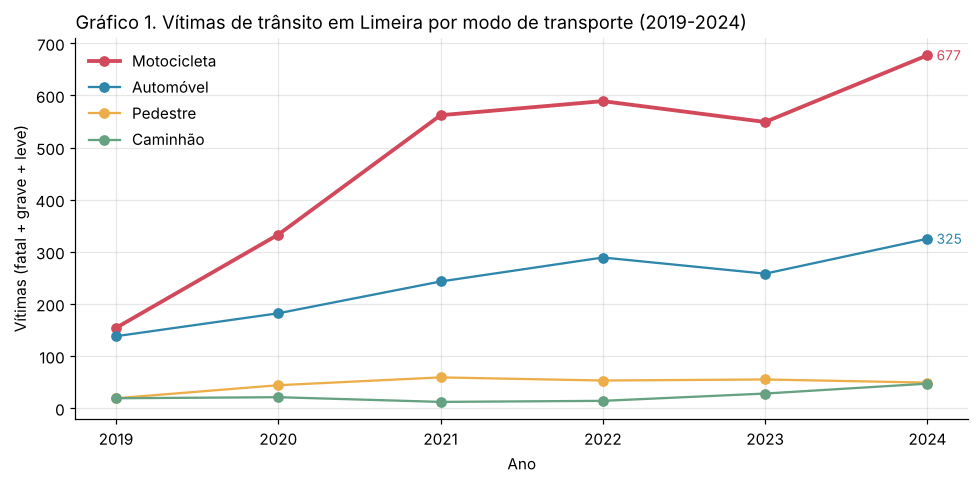

In [25]:
# Gráfico 1: evolução das vítimas por modo
fig, ax = plt.subplots(figsize=(9, 4.5))
for m in ["Motocicleta", "Automóvel", "Pedestre", "Caminhão"]:
    ax.plot(serie.index, serie[m], marker="o", lw=2.5 if m == "Motocicleta" else 1.5, color=COR[m], label=m)
for m in ["Motocicleta", "Automóvel"]:
    ax.annotate(str(serie[m].iloc[-1]), (serie.index[-1], serie[m].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=COR[m], fontsize=9)
ax.set_title("Gráfico 1. Vítimas de trânsito em Limeira por modo de transporte (2019-2024)", loc="left")
ax.set_xlabel("Ano")
ax.set_ylabel("Vítimas (fatal + grave + leve)")
ax.set_xticks(serie.index)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

A moto tem mais vítimas que qualquer outro modo em todos os anos, e a distância para o carro aumentou. Em 2024 foram 677 motociclistas feridos contra 325 ocupantes de carro, mais que o dobro. O valor de 2019 é baixo em parte porque a base ainda estava começando a registrar acidentes sem morte.

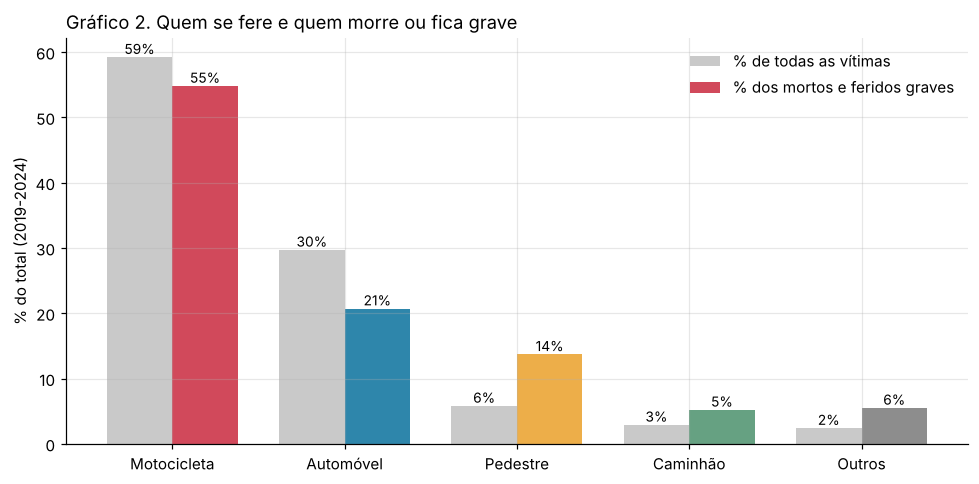

In [26]:
# Gráfico 2: participação nas vítimas x nos casos graves
ordem = ["Motocicleta", "Automóvel", "Pedestre", "Caminhão", "Outros"]
pm = por_modo.reindex(ordem)
x = np.arange(len(ordem))
fig, ax = plt.subplots(figsize=(9, 4.5))
b1 = ax.bar(x - 0.19, pm["% das vítimas"], 0.38, color="#c9c9c9", label="% de todas as vítimas")
b2 = ax.bar(x + 0.19, pm["% dos casos graves"], 0.38, color=[COR[o] for o in ordem], label="% dos mortos e feridos graves")
ax.bar_label(b1, fmt="%.0f%%", fontsize=9)
ax.bar_label(b2, fmt="%.0f%%", fontsize=9)
ax.set_xticks(x, ordem)
ax.set_ylabel("% do total (2019-2024)")
ax.set_title("Gráfico 2. Quem se fere e quem morre ou fica grave", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Motociclistas lideram tanto entre os feridos (59%) quanto entre os mortos e feridos graves (55%). O pedestre faz o caminho contrário: é 6% das vítimas, mas 14% dos casos graves, porque quando é atingido o resultado costuma ser pior. O carro cai de 30% para 21%, já que a carroceria protege quem está dentro.

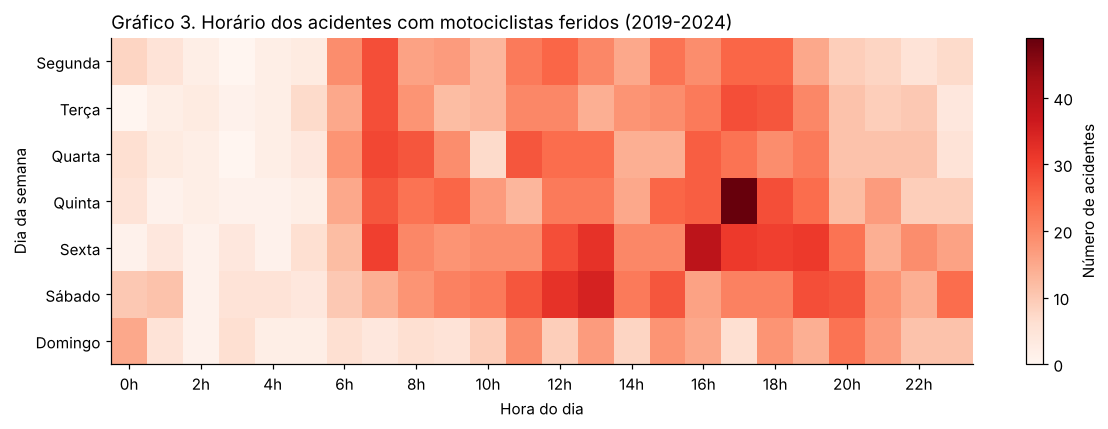

In [27]:
# Gráfico 3: dia da semana x hora
dias = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado", "Domingo"]
acid_moto = moto.drop_duplicates("id_sinistro").dropna(subset=["hora"])
mapa = pd.crosstab(acid_moto["dia_da_semana"], acid_moto["hora"]).reindex(dias).reindex(columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(mapa, aspect="auto", cmap="Reds")
ax.set_yticks(range(7), [d.replace("-feira", "") for d in dias])
ax.set_xticks(range(0, 24, 2), [f"{h}h" for h in range(0, 24, 2)])
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Dia da semana")
ax.grid(False)
ax.set_title("Gráfico 3. Horário dos acidentes com motociclistas feridos (2019-2024)", loc="left")
fig.colorbar(im, ax=ax, label="Número de acidentes")
plt.tight_layout()
plt.show()

Os acidentes acompanham o horário de trabalho. Há um pico às 7h, na ida, e outro entre 16h e 19h, na volta, mais forte de quinta a sábado. O horário com mais acidentes é quinta-feira às 17h. No sábado o pico muda para 12h-13h e continua à noite, que é o horário típico de entrega de comida. Isso confirma que o público da solução é quem usa a moto para trabalhar.

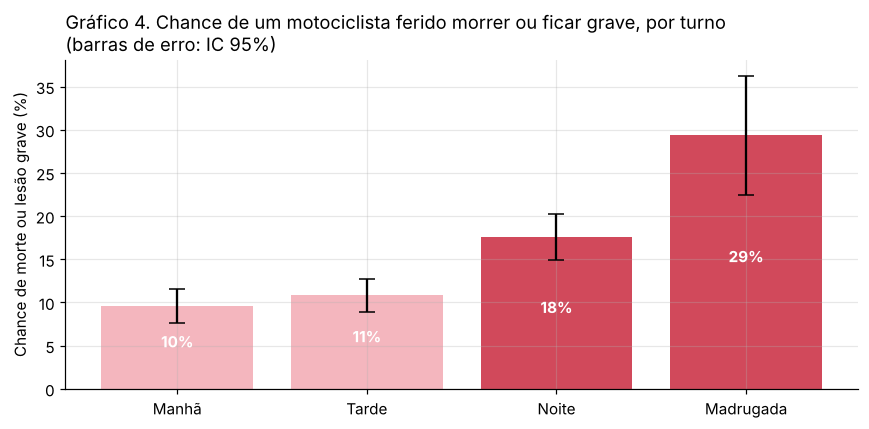

In [28]:
# Gráfico 4: chance de caso grave por turno
p_t = np.array([prob(moto.loc[moto["turno"] == t, "grave"].sum(), (moto["turno"] == t).sum()) for t in turnos])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(4), p_t[:, 0] * 100, color=["#f4b6be", "#f4b6be", COR["Motocicleta"], COR["Motocicleta"]],
       yerr=[(p_t[:, 0] - p_t[:, 1]) * 100, (p_t[:, 2] - p_t[:, 0]) * 100], capsize=5)
for i, val in enumerate(p_t[:, 0]):
    ax.text(i, val * 50, f"{val:.0%}", ha="center", color="white", fontweight="bold")
ax.set_xticks(range(4), ["Manhã", "Tarde", "Noite", "Madrugada"])
ax.set_ylabel("Chance de morte ou lesão grave (%)")
ax.set_title("Gráfico 4. Chance de um motociclista ferido morrer ou ficar grave, por turno\n(barras de erro: IC 95%)", loc="left")
plt.tight_layout()
plt.show()

De dia, cerca de 10% dos motociclistas feridos morrem ou ficam graves. À noite são 18% e de madrugada 29%. Os intervalos de confiança do dia e da madrugada não se encostam. Enquanto o gráfico 3 mostra quando há mais acidentes, este mostra quando eles são mais graves, e por isso a solução precisa de dois alertas: um por lugar e outro por horário.

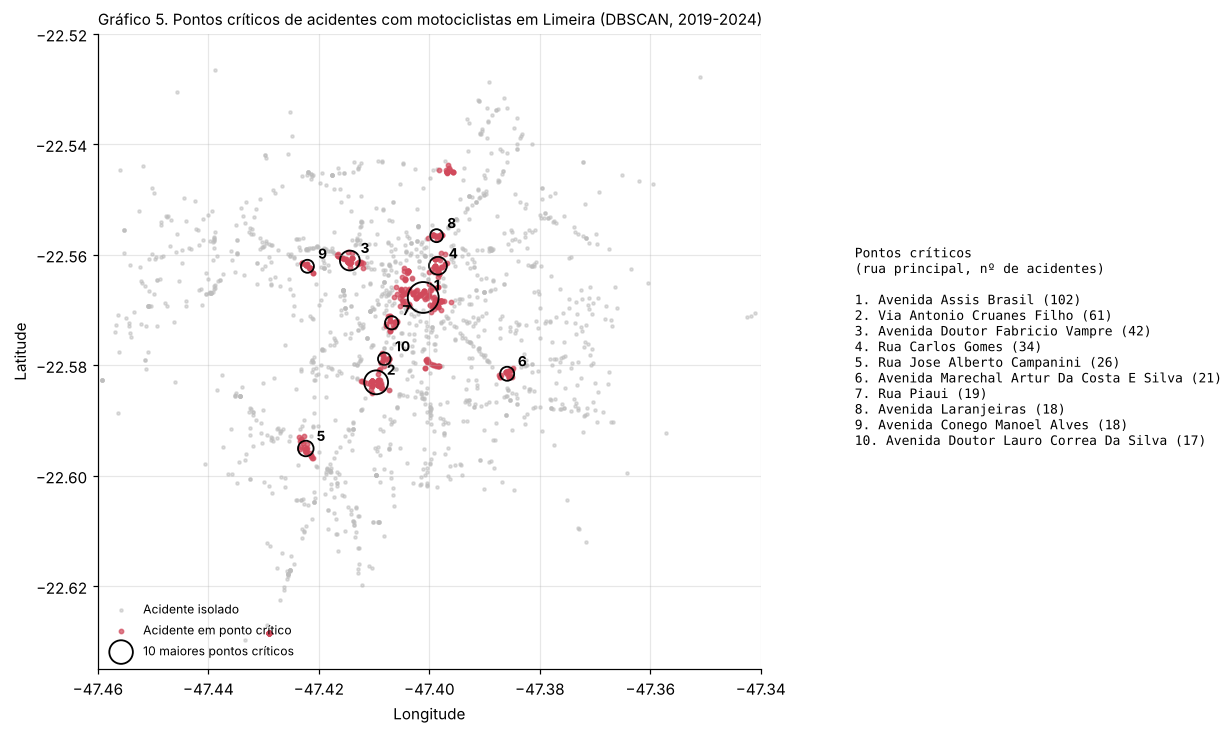

In [29]:
# Gráfico 5: mapa dos pontos críticos
fig, ax = plt.subplots(figsize=(13, 7.5))
fig.subplots_adjust(right=0.68)
isolados = pts[pts["grupo"] < 0]
ax.scatter(isolados["longitude"], isolados["latitude"], s=4, color="#bdbdbd", alpha=0.5, label="Acidente isolado")
top = hot.head(10)
no_grupo = pts[pts["grupo"] >= 0]
ax.scatter(no_grupo["longitude"], no_grupo["latitude"], s=8, color=COR["Motocicleta"], alpha=0.7,
           label="Acidente em ponto crítico")
ax.scatter(top["lon"], top["lat"], s=top["acidentes"] * 4, facecolors="none", edgecolors="black",
           linewidths=1.2, label="10 maiores pontos críticos")
for i, r in top.iterrows():
    ax.annotate(str(i), (r["lon"], r["lat"]), xytext=(7, 5), textcoords="offset points",
                fontsize=9, fontweight="bold")
lista = "\n".join(f"{i}. {r['rua_principal'].title()} ({r['acidentes']})" for i, r in top.iterrows())
fig.text(0.70, 0.5, "Pontos críticos\n(rua principal, nº de acidentes)\n\n" + lista,
         va="center", fontsize=8.5, family="monospace")
ax.set_xlim(-47.46, -47.34)
ax.set_ylim(-22.635, -22.52)
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Gráfico 5. Pontos críticos de acidentes com motociclistas em Limeira (DBSCAN, 2019-2024)",
             loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.show()

Os pontos críticos ficam no centro e nos grandes eixos da cidade: Av. Assis Brasil, Via Antônio Cruanes Filho, Av. Fabrício Vampré, Rua Carlos Gomes e Av. Laranjeiras. Cada círculo é um trecho de poucos quarteirões onde a prefeitura pode agir (semáforo, faixa, iluminação, fiscalização) e onde o aplicativo avisaria o motociclista. Os pontos cinza são acidentes que não se repetem no mesmo lugar.

## 7. Conclusões

### Resultado das hipóteses

| Hipótese | Resultado | Principal evidência |
|---|---|---|
| H1. Motociclistas são a maioria das vítimas e se machucam mais | Sustentada | 59% das vítimas; 13,5% de casos graves contra 10,2% no carro (RR 1,33; teste A) |
| H2. Vítimas são homens jovens, com destaque para entregadores | Sustentada, com ajuste | 77% homens, mediana de 29 anos (teste D). Entregador é a profissão nº 1, mas são 15% das vítimas |
| H3. Acidentes à noite são mais graves | Sustentada | 10% de casos graves de dia, 18% à noite e 29% de madrugada (testes B e C) |
| H4. Acidentes se concentram em poucos pontos | Sustentada | 14 pontos críticos com 23,5% dos acidentes; 9% das ruas com metade dos casos |
| H5. O número de motociclistas feridos está crescendo | Sustentada, com ressalva | +6,4% ao ano entre 2021 e 2024 e recorde em 2024; o salto de 2019-2020 mistura mudança na base e pandemia |

Ficou em aberto o motivo de a noite ser mais grave e se entregadores correm mais risco por quilômetro rodado, já que a base não diz quanto cada pessoa roda. Esses pontos entram no questionário com motociclistas.

### Indicadores obtidos

| Indicador | Valor |
|---|---|
| Mortes no trânsito por ano (média 2015-2025) | 48,6 (16,7 por 100 mil hab.) |
| Motociclistas feridos em 2024 | 677 (232 por 100 mil hab.) |
| Casos graves de motociclistas em 2024 | 36,3 por 100 mil hab. |
| Chance de caso grave para motociclista ferido | 13,5% (19,7% à noite e de madrugada) |
| Pontos críticos (DBSCAN) | 14, com 23,5% dos acidentes urbanos com moto |

### O que isso muda na solução

A análise sustenta as três partes da proposta RotaSegura Limeira:

1. **Alerta por lugar.** Os 14 pontos críticos viram zonas de atenção, e o motociclista recebe um aviso sonoro ou por WhatsApp ao se aproximar, sem precisar olhar para a tela.
2. **Alerta por horário.** Como a chance de caso grave dobra à noite, o aviso fica mais forte nesse período e no fim de semana.
3. **Painel para a prefeitura.** Lista dos pontos críticos e das ruas com mais acidentes, para decidir onde colocar semáforo, iluminação ou fiscalização.

Os dados também mudaram duas coisas na proposta:
- **O público ficou maior.** Em vez de só entregadores de aplicativo, a solução atende quem usa a moto para trabalhar. Os entregadores continuam sendo o primeiro público, porque rodam mais e em mais horários.
- **Os pedestres entraram no painel.** Como têm a maior chance de caso grave (35%), o painel da prefeitura também mostra as travessias próximas aos pontos críticos.

**Meta de impacto:** reduzir os casos graves de motociclistas por 100 mil habitantes (36,3 em 2024) e a parcela de acidentes que acontece nos pontos críticos, acompanhando os dois números a cada atualização do Infosiga.

## 8. Limitações e uso responsável dos dados

**Limitações**
- O período útil para feridos é curto (2019 a 2024) e inclui a pandemia. 2025 e 2026 ficaram de fora por estarem incompletos.
- Muitos acidentes leves não geram boletim de ocorrência, principalmente com motoboys que voltam a trabalhar no mesmo dia. O número real de motociclistas feridos provavelmente é maior.
- Profissão, idade e localização têm informação faltando. Cerca de 22% dos acidentes não têm uma localização confiável e ficaram fora do mapa, então a quantidade de entregadores e de acidentes por ponto é um mínimo.
- Não sabemos quantos quilômetros cada grupo roda. O risco calculado é a gravidade quando o acidente acontece, não o risco por quilômetro.
- Correlação não é causa. A base mostra que a noite é mais grave, mas não explica o motivo.
- Usamos a população do Censo 2022 para todos os anos, o que é uma aproximação.

**Vieses que podem deixar grupos de fora**
- Bairros com menos policiamento ou menos registros podem parecer mais seguros do que são. Por isso a solução prevê que os próprios motociclistas possam marcar trechos perigosos, sem depender só do dado oficial.
- Entregadores informais, que não usam aplicativo de entrega, podem não ser alcançados por uma solução que depende desses apps. Por isso o canal principal é WhatsApp ou SMS.

**Privacidade (LGPD)**
- Os dados do Infosiga são públicos e não identificam as pessoas: não têm nome, CPF, placa ou endereço da vítima. Usamos apenas idade, sexo e profissão, sempre de forma agregada.
- Na solução, a localização do motociclista seria usada só no próprio celular para comparar com os pontos críticos, sem guardar o trajeto. O uso dependeria de consentimento (art. 7º, I, da LGPD) e poderia ser desligado a qualquer momento. Os relatos dos usuários seriam guardados sem identificação e só divulgados de forma agregada por trecho.